# Results: angular clustering of CEERS high-z galaxies

Collects every run of `run_pipeline.py` and shows:

1. Results table: N, $A_w$, $r_0$, $b_g$, $M_h$ per redshift bin (saved as CSV and LaTeX)
2. $w(\theta)$ with the fitted power law, one panel per bin
3. $A_w$, $r_0$, $b_g$ and $\log M_h$ against redshift
4. Galaxy bias against halo-bias tracks of fixed mass
5. Luminosity function used (`inputs/lf_table.csv`)
6. Completeness $C(m)$ per bin
7. Data and random positions on the sky
8. Run logs

Results come from `summary/z*/summary_*.yaml`. A bin can have several runs (one per settings
hash), so by default the **newest run per (z, M_UV bin)** is used. To use another run, put its
tag in `PIN` in the next cell.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt
from IPython.display import display

# project root = first parent folder that has summary/ and codes/
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "summary").is_dir() and (p / "codes").is_dir())
sys.path.insert(0, str(ROOT / "codes"))
from run_pipeline import make_phi, load_lf_table, isotonic_decreasing
from halo_mass import halo_bias
from acf_estimator import _linear_growth_factor
from astropy.cosmology import FlatLambdaCDM

with open(ROOT / "codes" / "parameters.yaml") as f:
    CFG = yaml.safe_load(f)
COSMO = CFG["cosmology"]
BETA = CFG["acf"]["beta"]
cosmo = FlatLambdaCDM(H0=COSMO["H0"], Om0=COSMO["Om0"])

PIN = {}            # e.g. {(11.0, (-23.5, -17.5)): "z11.00_seed42_db3a299a_M-23.5_-17.5"}
DETECTION_SIGMA = 2.0   # A_w / A_w_err below this -> shown as an upper limit

# categorical colours, assigned to bins in a fixed order (never cycled)
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, MUTED, GRID = "#1f1f1e", "#6b6a64", "#e4e3de"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "lines.linewidth": 2,
    "lines.markersize": 7, "legend.frameon": False, "font.size": 10,
})
print("project:", ROOT)

project: /Users/mac/Desktop/JupyterNoteBooks/astro_env/git_repo/project/2PACF_filter_actual_sources


## 1. Results table

In [16]:
rows = []
for f in sorted((ROOT / "summary").glob("z*/summary_*.yaml")):
    with open(f) as fh:
        s = yaml.safe_load(fh)
    s["tag"] = f.stem.removeprefix("summary_")
    s["file"] = f
    s["mtime"] = f.stat().st_mtime
    rows.append(s)
runs = pd.DataFrame(rows)
runs["M_bin"] = runs["M_UV_bin"].map(tuple)
runs["theta_min"] = runs["theta_bins_arcsec"].map(lambda t: t[0])
runs["theta_max"] = runs["theta_bins_arcsec"].map(lambda t: t[1])
for col in ["log10_Mh_h_inv_Msun", "log10_Mh_lo", "log10_Mh_hi", "A_w_raw", "contamination_fraction"]:
    if col not in runs:
        runs[col] = np.nan          # runs made before these fields existed

def pick(group):
    key = (group.name[0], group.name[1])
    if key in PIN:
        return group[group["tag"] == PIN[key]].iloc[0]
    return group.sort_values("mtime").iloc[-1]

res = (runs.groupby(["z_drop", "M_bin"], group_keys=False).apply(pick)
           .sort_values("z_eff").reset_index(drop=True))
res["snr"] = res["A_w"] / res["A_w_err"]
res["detected"] = res["snr"] >= DETECTION_SIGMA
res["A_w_upper"] = np.where(res["detected"], np.nan, np.maximum(res["A_w"], 0) + DETECTION_SIGMA * res["A_w_err"])
res["colour"] = [SERIES[i % len(SERIES)] for i in range(len(res))]

print(f"{len(runs)} runs found, {len(res)} used (newest per bin unless pinned)")
show = res[["z_drop", "z_eff", "M_bin", "n_data", "theta_min", "theta_max", "A_w", "A_w_err", "snr",
            "r0_h_inv_mpc", "r0_err_h_inv_mpc", "bias", "bias_err",
            "log10_Mh_h_inv_Msun", "log10_Mh_lo", "log10_Mh_hi", "tag"]]
display(show.round(3))

25 runs found, 5 used (newest per bin unless pinned)


/var/folders/pb/ymqq53c52qjcjjgcm6bmkq3w0000gn/T/ipykernel_24730/3403341197.py:23: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  res = (runs.groupby(["z_drop", "M_bin"], group_keys=False).apply(pick)


,z_drop,z_eff,M_bin,n_data,theta_min,theta_max,A_w,A_w_err,snr,r0_h_inv_mpc,r0_err_h_inv_mpc,bias,bias_err,log10_Mh_h_inv_Msun,log10_Mh_lo,log10_Mh_hi,tag
0,8.0,7.905,"(-23.5, -17.5)",776,10.0,200.0,0.260,0.203,1.282,1.172,0.571,2.299,0.897,7.744,NaN,8.719,z8.00_seed42_aebfcc78_M-23.5_-17.5
1,9.0,8.895,"(-23.5, -17.5)",307,10.0,200.0,0.949,0.548,1.733,2.378,0.858,4.500,1.298,9.076,8.191,9.645,z9.00_seed42_12212687_M-23.5_-17.5
2,10.0,9.898,"(-23.5, -17.5)",49,8.0,200.0,-3.522,0.881,-3.998,NaN,NaN,NaN,NaN,NaN,NaN,NaN,z10.00_seed42_78b2191b_M-23.5_-17.5
3,11.0,10.923,"(-23.5, -17.5)",115,10.0,200.0,0.348,1.194,0.291,1.121,2.406,2.970,5.099,6.903,NaN,9.529,z11.00_seed42_96717176_M-23.5_-17.5
4,12.0,11.895,"(-23.5, -17.5)",68,10.0,200.0,0.415,2.056,0.202,1.131,3.503,3.235,8.017,6.708,NaN,9.860,z12.00_seed42_0a6552b7_M-23.5_-17.5


In [17]:
# all runs, to see how results moved between settings
display(runs.sort_values(["z_drop", "mtime"])[["z_drop", "z_eff", "M_bin", "n_data", "theta_min",
                                                 "A_w", "A_w_err", "r0_h_inv_mpc", "bias", "tag"]].round(3))

,z_drop,z_eff,M_bin,n_data,theta_min,A_w,A_w_err,r0_h_inv_mpc,bias,tag
18,8.0,7.905,"(-23.5, -17.5)",774,10.0,0.261,0.213,1.174,2.303,z8.00_seed42_69efb2da_M-23.5_-17.5
21,8.0,7.899,"(-23.5, -17.5)",397,10.0,0.291,0.340,1.247,2.415,z8.00_seed42_f2e15542_M-23.5_-17.5
16,8.0,7.905,"(-23.5, -17.5)",142,10.0,-0.274,1.061,NaN,NaN,z8.00_seed42_35ae3cb2_M-23.5_-17.5
17,8.0,7.901,"(-23.5, -17.5)",113,10.0,-0.131,1.397,NaN,NaN,z8.00_seed42_3c5b7900_M-23.5_-17.5
15,8.0,7.905,"(-23.5, -17.5)",774,10.0,0.261,0.213,1.174,2.303,z8.00_seed42_09a4d567_M-23.5_-17.5
19,8.0,7.905,"(-23.5, -17.5)",926,10.0,0.157,0.180,0.856,1.789,z8.00_seed42_94b9ee18_M-23.5_-17.5
20,8.0,7.905,"(-23.5, -17.5)",776,10.0,0.260,0.203,1.172,2.299,z8.00_seed42_aebfcc78_M-23.5_-17.5
24,9.0,8.895,"(-23.5, -17.5)",305,10.0,0.932,0.572,2.351,4.459,z9.00_seed42_4ac6bad6_M-23.5_-17.5
23,9.0,8.895,"(-23.5, -17.5)",351,10.0,1.192,0.552,2.741,5.042,z9.00_seed42_3a33b322_M-23.5_-17.5
22,9.0,8.895,"(-23.5, -17.5)",307,10.0,0.949,0.548,2.378,4.500,z9.00_seed42_12212687_M-23.5_-17.5


In [18]:
def pm(v, e, nd=3):
    return "--" if not np.isfinite(v) else f"${v:.{nd}f}\\pm{e:.{nd}f}$"

def mh(r):
    if not np.isfinite(r.log10_Mh_h_inv_Msun):
        return "--"
    lo = r.log10_Mh_h_inv_Msun - r.log10_Mh_lo if np.isfinite(r.log10_Mh_lo) else np.nan
    hi = r.log10_Mh_hi - r.log10_Mh_h_inv_Msun
    lo_s = f"{lo:.2f}" if np.isfinite(lo) else "?"
    return f"${r.log10_Mh_h_inv_Msun:.2f}^{{+{hi:.2f}}}_{{-{lo_s}}}$"

table = pd.DataFrame({
    "Redshift": res["z_eff"].round(2),
    "$N$": res["n_data"],
    "$A_w$": [pm(a, e) if d else f"$<{u:.2f}$" for a, e, d, u in zip(res.A_w, res.A_w_err, res.detected, res.A_w_upper)],
    "$r_0$ ($h^{-1}$ Mpc)": [pm(a, e) for a, e in zip(res.r0_h_inv_mpc, res.r0_err_h_inv_mpc)],
    "$b_g$": [pm(a, e) for a, e in zip(res.bias, res.bias_err)],
    "$\\log_{10} M_h$ ($h^{-1}M_\\odot$)": [mh(r) for r in res.itertuples()],
})
display(table)

out_csv = ROOT / "summary" / "results_table.csv"
res.drop(columns=["file", "colour"]).to_csv(out_csv, index=False)
latex = table.to_latex(index=False, escape=False, column_format="r" * table.shape[1])
(ROOT / "summary" / "results_table.tex").write_text(latex)
print(latex)
print("saved", out_csv, "and results_table.tex")

,Redshift,$N$,$A_w$,$r_0$ ($h^{-1}$ Mpc),$b_g$,$\log_{10} M_h$ ($h^{-1}M_\odot$)
0,7.91,776,$<0.67$,$1.172\pm0.571$,$2.299\pm0.897$,$7.74^{+0.98}_{-?}$
1,8.90,307,$<2.04$,$2.378\pm0.858$,$4.500\pm1.298$,$9.08^{+0.57}_{-0.88}$
2,9.90,49,$<1.76$,--,--,--
3,10.92,115,$<2.73$,$1.121\pm2.406$,$2.970\pm5.099$,$6.90^{+2.63}_{-?}$
4,11.89,68,$<4.53$,$1.131\pm3.503$,$3.235\pm8.017$,$6.71^{+3.15}_{-?}$


\begin{tabular}{rrrrrr}
\toprule
Redshift & $N$ & $A_w$ & $r_0$ ($h^{-1}$ Mpc) & $b_g$ & $\log_{10} M_h$ ($h^{-1}M_\odot$) \\
\midrule
7.910000 & 776 & $<0.67$ & $1.172\pm0.571$ & $2.299\pm0.897$ & $7.74^{+0.98}_{-?}$ \\
8.900000 & 307 & $<2.04$ & $2.378\pm0.858$ & $4.500\pm1.298$ & $9.08^{+0.57}_{-0.88}$ \\
9.900000 & 49 & $<1.76$ & -- & -- & -- \\
10.920000 & 115 & $<2.73$ & $1.121\pm2.406$ & $2.970\pm5.099$ & $6.90^{+2.63}_{-?}$ \\
11.890000 & 68 & $<4.53$ & $1.131\pm3.503$ & $3.235\pm8.017$ & $6.71^{+3.15}_{-?}$ \\
\bottomrule
\end{tabular}

saved /Users/mac/Desktop/JupyterNoteBooks/astro_env/git_repo/project/2PACF_filter_actual_sources/summary/results_table.csv and results_table.tex


## 2. $w(\theta)$ per bin

Points: Landy–Szalay $w(\theta)$ with bootstrap errors. Line: fitted $A_w(\theta^{-\beta} - \mathrm{IC}/A_w)$
(raw amplitude, i.e. before any contamination correction, since the points are raw too).
Open points: bins left out of the fit (RR below `min_RR_counts`).

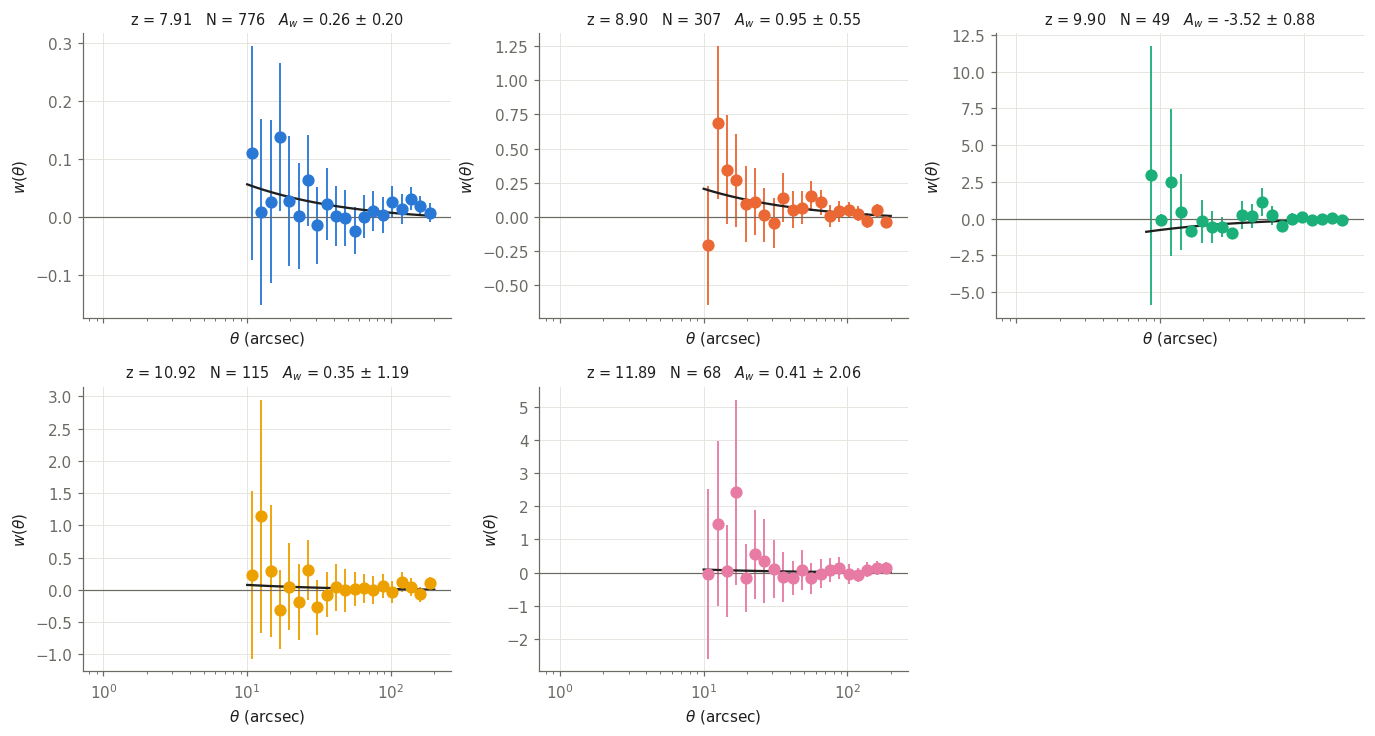

In [19]:
n = len(res)
ncol = min(3, n)
nrow = int(np.ceil(n / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(4.2 * ncol, 3.4 * nrow), squeeze=False, sharex=True)
min_rr = CFG["acf"]["min_RR_counts"]

for ax, r in zip(axes.flat, res.itertuples()):
    acf = pd.read_csv(ROOT / "outputs" / f"z{r.z_drop:.2f}" / f"acf_results_{r.tag}.csv")
    used = acf["RR"] >= min_rr
    ax.errorbar(acf.theta_arcsec[used], acf.w_obs[used], acf.w_err[used], fmt="o", color=r.colour, capsize=0, lw=1.2)
    ax.errorbar(acf.theta_arcsec[~used], acf.w_obs[~used], acf.w_err[~used], fmt="o", mfc="white", color=r.colour, lw=1.2)
    A_raw = r.A_w_raw if np.isfinite(r.A_w_raw) else r.A_w
    th = np.geomspace(acf.theta_lo.min(), acf.theta_hi.max(), 200)
    ax.plot(th, A_raw * (th ** -BETA - r.ic_over_Aw), color=INK, lw=1.5)
    ax.axhline(0, color=MUTED, lw=0.8)
    ax.set_xscale("log")
    ax.set_title(f"z = {r.z_eff:.2f}   N = {r.n_data}   $A_w$ = {r.A_w:.2f} ± {r.A_w_err:.2f}", fontsize=9.5, color=INK)
    ax.set_xlabel(r"$\theta$ (arcsec)")
    ax.set_ylabel(r"$w(\theta)$")
for ax in axes.flat[n:]:
    ax.set_visible(False)
fig.tight_layout()
fig.savefig(ROOT / "summary" / "wtheta_all_bins.png", bbox_inches="tight")
plt.show()

## 3. Results against redshift

One quantity per panel (no shared y-axes). Filled points: detections ($A_w/\sigma \geq$ `DETECTION_SIGMA`).
Arrows: upper limits on $A_w$ at that significance. $r_0$, $b_g$ and $M_h$ exist only where $A_w > 0$.

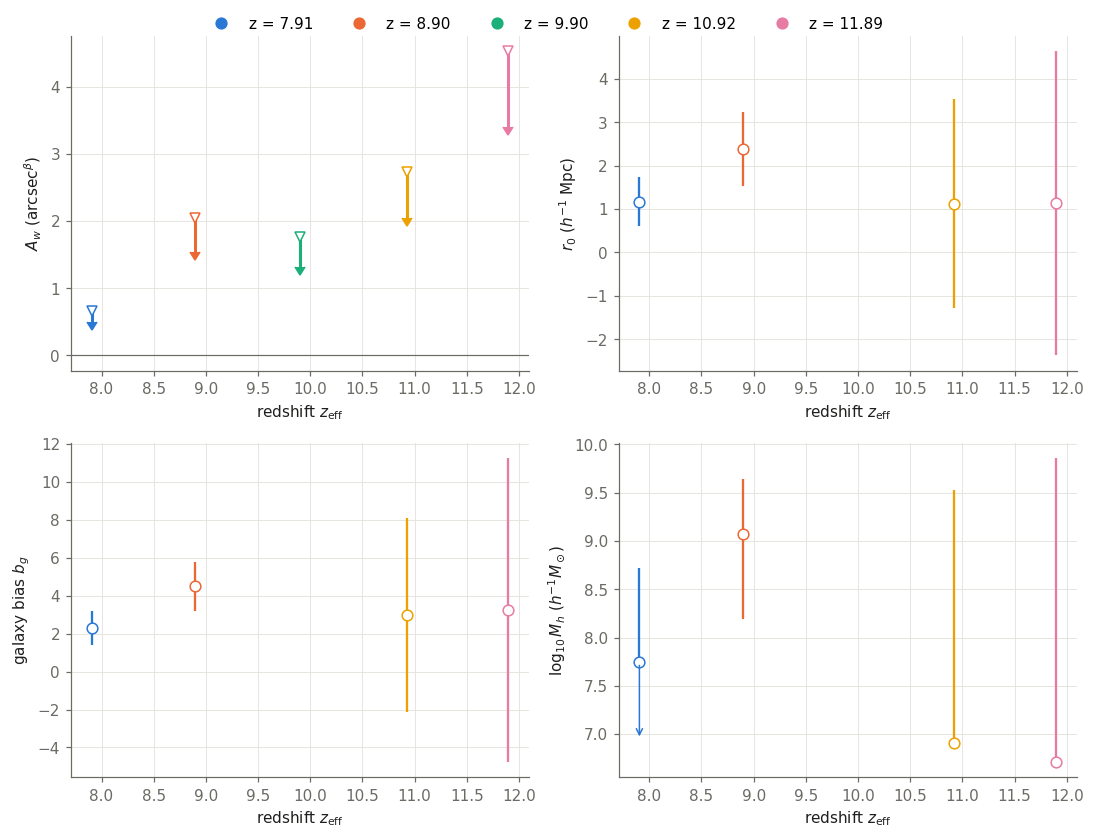

In [20]:
quantities = [
    ("A_w", "A_w_err", r"$A_w$ (arcsec$^{\beta}$)"),
    ("r0_h_inv_mpc", "r0_err_h_inv_mpc", r"$r_0$ ($h^{-1}$ Mpc)"),
    ("bias", "bias_err", r"galaxy bias $b_g$"),
    ("log10_Mh_h_inv_Msun", None, r"$\log_{10} M_h$ ($h^{-1} M_\odot$)"),
]
fig, axes = plt.subplots(2, 2, figsize=(10, 7.5))
for ax, (col, ecol, label) in zip(axes.flat, quantities):
    for r in res.itertuples():
        v = getattr(r, col)
        if col == "A_w" and not r.detected:
            ax.errorbar(r.z_eff, r.A_w_upper, yerr=0.25 * r.A_w_upper, uplims=True, fmt="v", color=r.colour, mfc="white")
            continue
        if not np.isfinite(v):
            continue
        if ecol:
            yerr = getattr(r, ecol)
        else:                                   # asymmetric mass range; NaN lower end = unconstrained
            lo = v - r.log10_Mh_lo if np.isfinite(r.log10_Mh_lo) else 0.0
            yerr = [[lo], [r.log10_Mh_hi - v]]
        ax.errorbar(r.z_eff, v, yerr=yerr, fmt="o", color=r.colour, capsize=0, lw=1.5,
                    mfc=r.colour if r.detected else "white")
        if ecol is None and not np.isfinite(r.log10_Mh_lo):
            ax.annotate("", (r.z_eff, v - 0.8), (r.z_eff, v), arrowprops=dict(arrowstyle="->", color=r.colour))
    ax.set_xlabel("redshift $z_{\\rm eff}$")
    ax.set_ylabel(label)
axes[0, 0].axhline(0, color=MUTED, lw=0.8)
handles = [plt.Line2D([], [], marker="o", ls="", color=r.colour, label=f"z = {r.z_eff:.2f}") for r in res.itertuples()]
fig.legend(handles=handles, loc="upper center", ncol=len(handles), bbox_to_anchor=(0.5, 1.02))
fig.tight_layout()
fig.savefig(ROOT / "summary" / "results_vs_z.png", bbox_inches="tight")
plt.show()

## 4. Galaxy bias against halo-bias tracks

Lines: $b_h(M, z)$ of halos of fixed mass (Tinker et al. 2010, or the model in `parameters.yaml`),
computed with `halo_mass.py`. A galaxy point lying on a track has that effective halo mass.

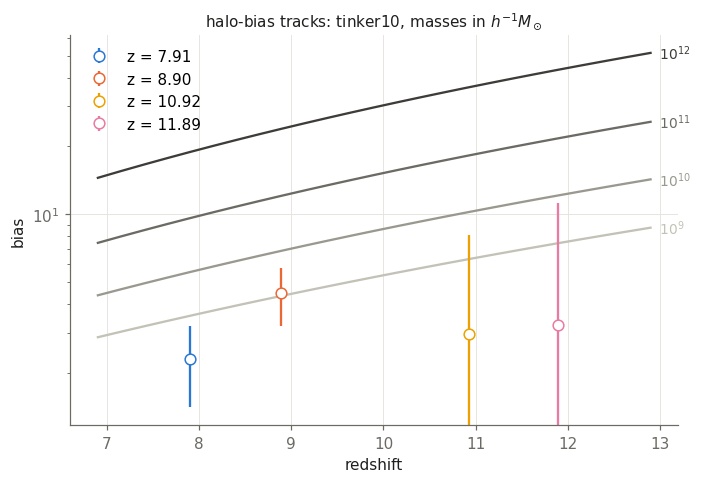

In [21]:
cosmo_pars = dict(Om0=COSMO["Om0"], Ob0=COSMO["Ob0"], h=COSMO["h"], ns=COSMO["ns"], sigma8_0=COSMO["sigma8_0"])
model = CFG.get("halo", {}).get("bias_model", "tinker10")
z_track = np.linspace(max(res.z_eff.min() - 1, 0.5), res.z_eff.max() + 1, 25)
growth = np.array([_linear_growth_factor(z, cosmo) for z in z_track])
track_masses = [9, 10, 11, 12]
greys = ["#c3c2b7", "#9a998f", "#6b6a64", "#3d3c38"]

fig, ax = plt.subplots(figsize=(6.5, 4.5))
for logM, g in zip(track_masses, greys):
    b = [halo_bias(10.0 ** logM, D, cosmo_pars, model)[0] for D in growth]
    ax.plot(z_track, b, color=g, lw=1.5)
    ax.text(z_track[-1], b[-1], f"  $10^{{{logM}}}$", color=g, va="center", fontsize=9)
for r in res.itertuples():
    if np.isfinite(r.bias):
        ax.errorbar(r.z_eff, r.bias, r.bias_err, fmt="o", color=r.colour, lw=1.5, capsize=0,
                    mfc=r.colour if r.detected else "white", label=f"z = {r.z_eff:.2f}")
ax.set_yscale("log")
ax.set_xlabel("redshift")
ax.set_ylabel("bias")
ax.set_title(f"halo-bias tracks: {model}, masses in $h^{{-1}} M_\\odot$", fontsize=10, color=INK)
ax.legend()
fig.tight_layout()
fig.savefig(ROOT / "summary" / "bias_vs_halo_tracks.png", bbox_inches="tight")
plt.show()

## 5. Luminosity function used

,z,M_star,M_star_err_lo,M_star_err_hi,phi_star,phi_star_err_lo,phi_star_err_hi,log_phi_star,log_phi_star_err_lo,log_phi_star_err_hi,alpha,alpha_err_lo,alpha_err_hi,type,reference,note
0,0.25,-18.481,0.230,0.230,5.080000e-03,2.110000e-03,3.620000e-03,-2.294,0.233,0.233,-1.308,0.065,0.065,extrapolated,NaN,Bouwens+21 best-fit evolution (fit range z~2-1...
1,0.75,-19.026,0.208,0.208,4.710000e-03,1.740000e-03,2.770000e-03,-2.327,0.201,0.201,-1.362,0.060,0.060,extrapolated,NaN,Bouwens+21 best-fit evolution (fit range z~2-1...
2,1.25,-19.571,0.190,0.190,4.250000e-03,1.380000e-03,2.050000e-03,-2.372,0.171,0.171,-1.418,0.056,0.056,extrapolated,NaN,Bouwens+21 best-fit evolution (fit range z~2-1...
3,1.75,-20.116,0.177,0.177,3.720000e-03,1.050000e-03,1.470000e-03,-2.429,0.144,0.144,-1.472,0.052,0.052,extrapolated,NaN,Bouwens+21 best-fit evolution (fit range z~2-1...
4,2.10,-20.280,0.090,0.090,4.000000e-03,4.000000e-04,5.000000e-04,-2.398,0.046,0.051,-1.520,0.030,0.030,real,Bouwens+21,NaN
5,2.25,-20.391,0.090,0.090,3.540000e-03,3.840000e-04,4.550000e-04,-2.450,0.050,0.052,-1.537,0.030,0.030,interpolated,NaN,linear between Bouwens+21 z=2.1 and z=2.9
6,2.75,-20.759,0.090,0.090,2.370000e-03,3.200000e-04,3.310000e-04,-2.625,0.063,0.057,-1.593,0.030,0.030,interpolated,NaN,linear between Bouwens+21 z=2.1 and z=2.9
7,2.90,-20.870,0.090,0.090,2.100000e-03,3.000000e-04,3.000000e-04,-2.678,0.067,0.058,-1.610,0.030,0.030,real,Bouwens+21,NaN
8,3.25,-20.893,0.086,0.086,1.930000e-03,2.570000e-04,2.660000e-04,-2.714,0.062,0.056,-1.641,0.030,0.030,interpolated,NaN,linear between Bouwens+21 z=2.9 and z=3.8
9,3.75,-20.927,0.081,0.081,1.710000e-03,2.050000e-04,2.240000e-04,-2.767,0.055,0.053,-1.686,0.030,0.030,interpolated,NaN,linear between Bouwens+21 z=2.9 and z=3.8


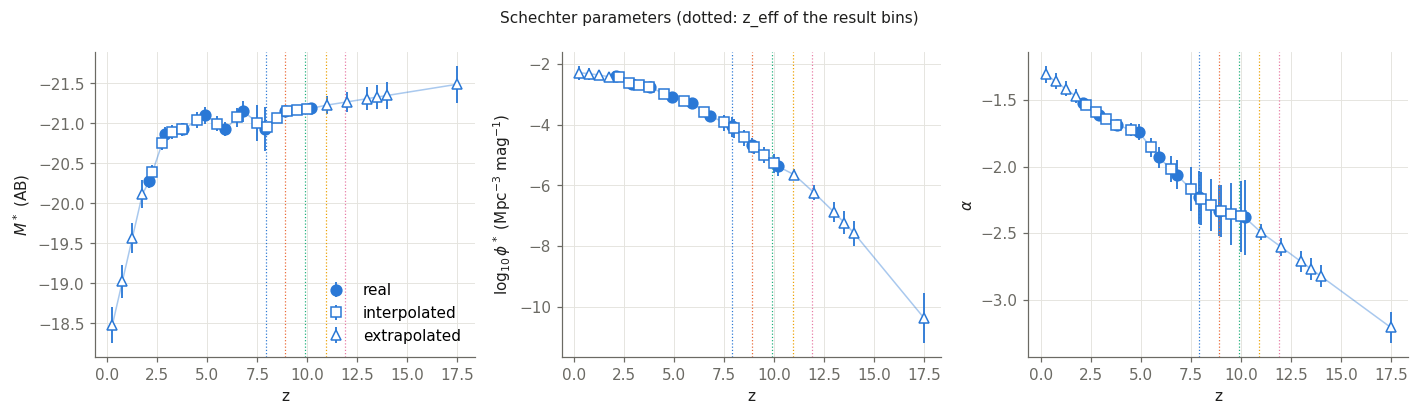

In [22]:
lf = load_lf_table(ROOT / "inputs" / "lf_table.csv")
display(lf)

styles = {"real": dict(marker="o", mfc=SERIES[0]), "interpolated": dict(marker="s", mfc="white"),
          "extrapolated": dict(marker="^", mfc="white")}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, p, label in zip(axes, ["M_star", "log_phi_star", "alpha"],
                        [r"$M^*$ (AB)", r"$\log_{10}\phi^*$ (Mpc$^{-3}$ mag$^{-1}$)", r"$\alpha$"]):
    for kind, st in styles.items():
        t = lf[lf["type"] == kind]
        lo, hi = (t.get(f"{p}_err_lo"), t.get(f"{p}_err_hi"))
        yerr = None if lo is None else [lo.fillna(0), hi.fillna(0)]
        ax.errorbar(t.z, t[p], yerr=yerr, ls="", color=SERIES[0], lw=1.2, capsize=0, label=kind, **st)
    ax.plot(lf.z, lf[p], color=SERIES[0], lw=1, alpha=0.4)
    for r in res.itertuples():
        ax.axvline(r.z_eff, color=r.colour, lw=0.8, ls=":")
    ax.set_xlabel("z")
    ax.set_ylabel(label)
axes[0].invert_yaxis()
axes[0].legend()
fig.suptitle("Schechter parameters (dotted: z_eff of the result bins)", color=INK, fontsize=10)
fig.tight_layout()
fig.savefig(ROOT / "summary" / "lf_parameters.png", bbox_inches="tight")
plt.show()

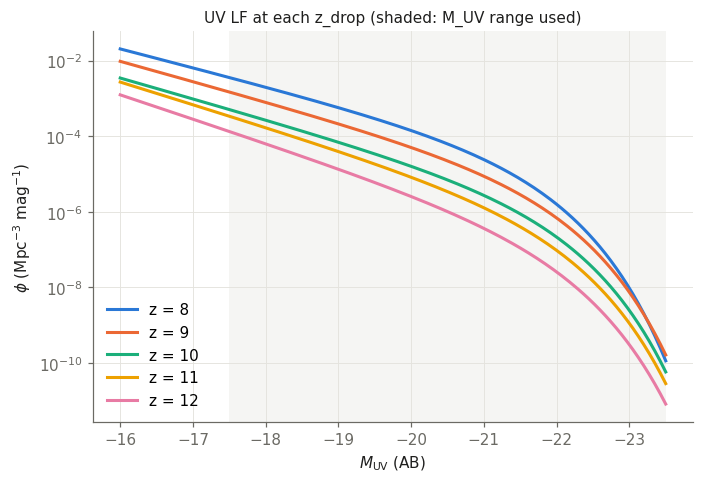

In [23]:
phi = make_phi(lf)
M = np.linspace(-23.5, -16, 200)
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for r in res.itertuples():
    ax.plot(M, phi(M, r.z_drop), color=r.colour, label=f"z = {r.z_drop:g}")
for lo_hi in sorted(set(res.M_bin)):
    ax.axvspan(*lo_hi, color=GRID, alpha=0.35, lw=0)
ax.set_yscale("log")
ax.set_xlabel(r"$M_{\rm UV}$ (AB)")
ax.set_ylabel(r"$\phi$ (Mpc$^{-3}$ mag$^{-1}$)")
ax.invert_xaxis()
ax.legend()
ax.set_title("UV LF at each z_drop (shaded: M_UV range used)", fontsize=10, color=INK)
fig.tight_layout()
fig.savefig(ROOT / "summary" / "lf_curves.png", bbox_inches="tight")
plt.show()

## 6. Completeness per bin (apparent magnitude, at the reference depth)

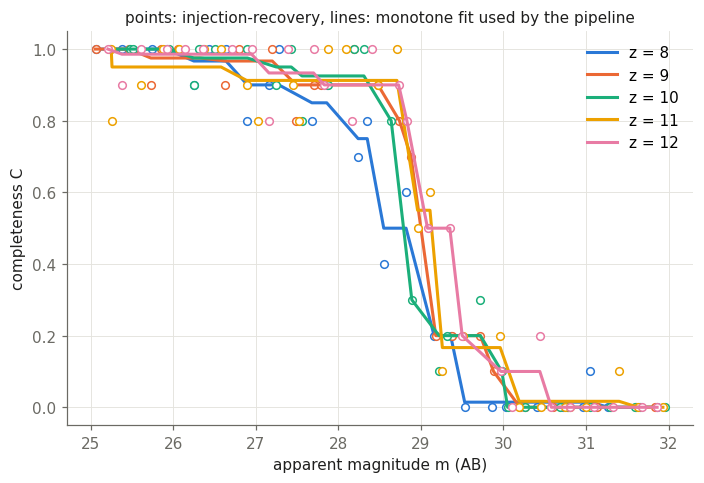

In [24]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for r in res.itertuples():
    f = ROOT / "inputs" / "completeness" / f"C_Mz_z{r.z_drop:.2f}.npz"
    if not f.exists():
        print("missing", f.name)
        continue
    d = np.load(f)
    o = np.argsort(d["M"])
    m, c = d["M"][o], np.clip(d["C"][o], 0, 1)
    ax.plot(m, c, "o", color=r.colour, mfc="white", ms=5)
    ax.plot(m, isotonic_decreasing(c), color=r.colour, label=f"z = {r.z_drop:g}")
ax.set_xlabel("apparent magnitude m (AB)")
ax.set_ylabel("completeness C")
ax.set_title("points: injection-recovery, lines: monotone fit used by the pipeline", fontsize=10, color=INK)
ax.legend()
fig.tight_layout()
fig.savefig(ROOT / "summary" / "completeness.png", bbox_inches="tight")
plt.show()

## 7. Data and randoms on the sky

Data: the bin catalogue after `survey.data_cuts` from `parameters.yaml` (the cuts as they are **now**,
which may differ from those of an older run). Randoms: the cached catalogue of the run used.

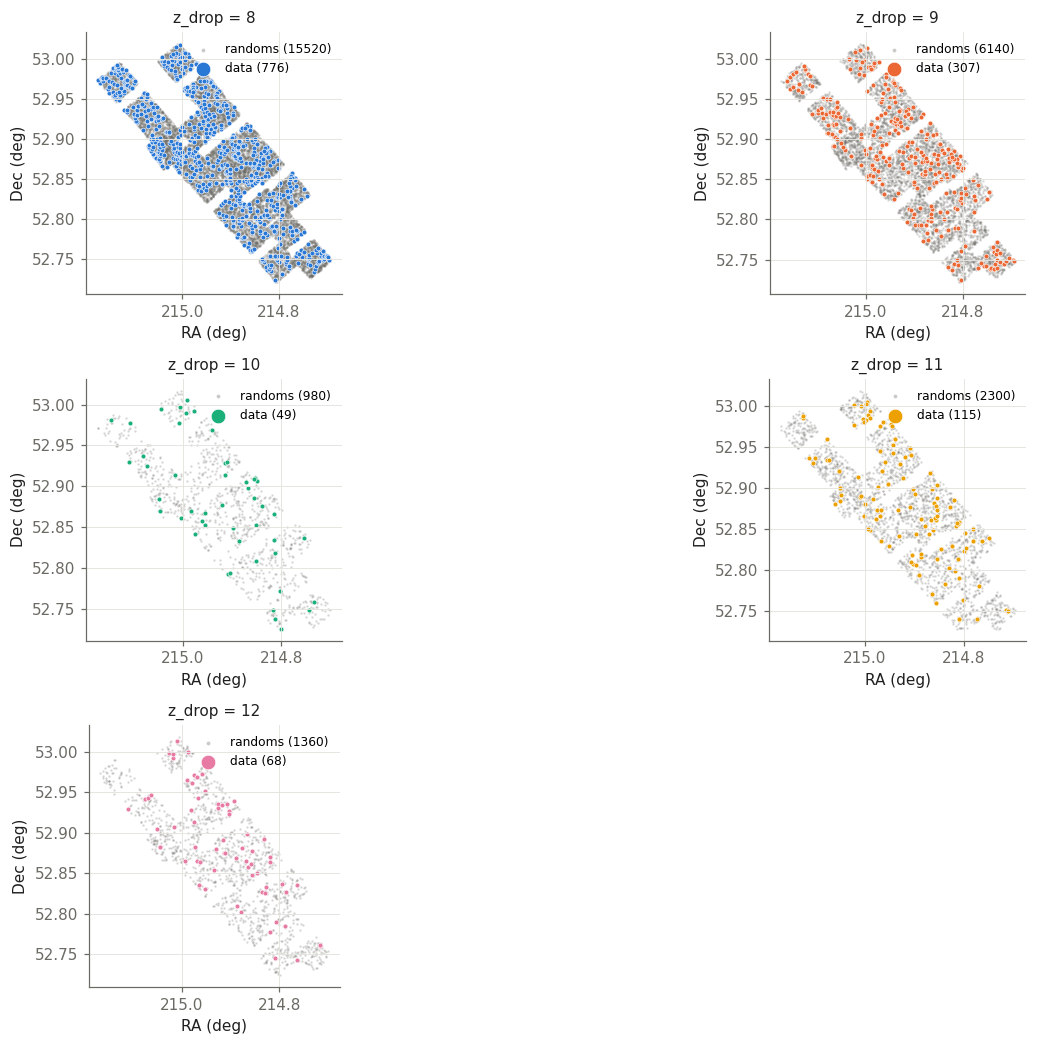

In [25]:
n = len(res)
ncol = min(2, n)
nrow = int(np.ceil(n / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(7 * ncol, 3.2 * nrow), squeeze=False)
sv = CFG["survey"]

for ax, r in zip(axes.flat, res.itertuples()):
    data = pd.read_csv(ROOT / "inputs" / "bins" / f"CEERS_z{r.z_drop:.2f}_selected.csv")
    for cut in sv.get("data_cuts") or []:
        data = data.query(cut)
    lo, hi = r.M_bin
    data = data[(data[sv["muv_col"]] >= lo) & (data[sv["muv_col"]] < hi)]
    rf = ROOT / "random_catalogs" / f"random_catalog_{r.tag}.csv"
    if rf.exists():
        rand = pd.read_csv(rf)
        ax.scatter(rand.ra, rand.dec, s=0.3, color=MUTED, alpha=0.25, rasterized=True, label=f"randoms ({len(rand)})")
    else:
        print("random catalogue not found:", rf.name)
    ax.scatter(data[sv["ra_col"]], data[sv["dec_col"]], s=10, color=r.colour, edgecolor="white", lw=0.4,
               label=f"data ({len(data)})")
    ax.invert_xaxis()
    ax.set_aspect(1 / np.cos(np.radians(data[sv["dec_col"]].mean())))
    ax.set_xlabel("RA (deg)")
    ax.set_ylabel("Dec (deg)")
    ax.set_title(f"z_drop = {r.z_drop:g}", fontsize=10, color=INK)
    ax.legend(loc="upper right", markerscale=3, fontsize=8)
for ax in axes.flat[n:]:
    ax.set_visible(False)
fig.tight_layout()
fig.savefig(ROOT / "summary" / "sky_data_randoms.png", bbox_inches="tight", dpi=150)
plt.show()

## 8. Run logs (last run of each bin)

In [26]:
for z in sorted(res.z_drop.unique()):
    log = ROOT / "summary" / f"z{z:.2f}" / f"run_log_z{z:.2f}.txt"
    print(f"===== z_drop = {z:g}  ({log.name})")
    print(log.read_text() if log.exists() else "  no log\n")

===== z_drop = 8  (run_log_z8.00.txt)
cut 'chi2_min <= 10': 1012 -> 846
cut 'USE == 1': 846 -> 841
z_drop = 8.0: N per M bin {(-23.5, -17.5): 776}, outside all bins 65
LF: lf_table.csv, nearest row z = 8.0 (interpolated): M* = -20.952, log phi* = -4.109, alpha = -2.24
data on finite depth pixels: 841 / 841
C(M_UV, z_drop) at M = -21, -19, -18, -17.5: [0.97 0.76 0.2  0.01]
building random catalogues, targets per M bin: [15520]
M -23.5 to -17.5: N = 776  A_w = 0.2598 +/- 0.2027  r0 = 1.172 +/- 0.5713 h^-1 Mpc  bias = 2.299 +/- 0.8968  (z_eff = 7.91)
    log10 M_h = 7.74 [nan, 8.72] h^-1 M_sun (tinker10)

===== z_drop = 9  (run_log_z9.00.txt)
cut 'chi2_min <= 10': 376 -> 323
cut 'USE == 1': 323 -> 320
z_drop = 9.0: N per M bin {(-23.5, -17.5): 307}, outside all bins 13
LF: lf_table.csv, nearest row z = 9.0 (interpolated): M* = -21.153, log phi* = -4.732, alpha = -2.334
data on finite depth pixels: 320 / 320
C(M_UV, z_drop) at M = -21, -19, -18, -17.5: [0.97 0.9  0.2  0.11]
building random